# audiowmark benchmark

Tests audiowmark (spread spectrum, 16-bit message) on 80 FMA-small tracks under 32 attack variants and checks whether the message survives.

The code is in the repo (`attacks/`, `methods/`, `scripts/`). This notebook gets the data, runs the scripts and looks at the results.

## 0. Setup (Colab)

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
%cd /content
!rm -rf music-watermark-benchmark
!git clone -q https://github.com/bohda6na/music-watermark-benchmark.git
%cd /content/music-watermark-benchmark
!pip install -q -r requirements.txt

/content
/content/music-watermark-benchmark
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.2 which is incompatible.
pytensor 2.38.3 requires numba<=0.65.1,>=0.58, but you have numba 0.68.0 which is incompatible.


pip changes the numpy and pandas versions that Colab already loaded (and may print a pandas version warning). Restart the session now (Runtime > Restart session), then run from section 1.

## 1. Data

FMA-small: 8000 tracks, 30 s each, 8 genres (https://github.com/mdeff/fma). The audio is not stored in the repo.

In [1]:
%cd /content/music-watermark-benchmark
!wget -q https://os.unil.cloud.switch.ch/fma/fma_metadata.zip -O /content/fma_metadata.zip
!wget -q https://os.unil.cloud.switch.ch/fma/fma_small.zip -O /content/fma_small.zip
!unzip -q -o /content/fma_metadata.zip -d /content

/content/music-watermark-benchmark


In [2]:
# checksum from the FMA readme
!echo "ade154f733639d52e35e32f5593efe5be76c6d70  /content/fma_small.zip" | sha1sum -c -

/content/fma_small.zip: OK


## 2. Test subset

First 10 tracks (sorted by `track_id`) of each genre = 80 tracks. Rebuilt here and compared with `data/selected_80.csv`.

In [3]:
import pandas as pd

t = pd.read_csv("/content/fma_metadata/tracks.csv", index_col=0, header=[0, 1])
small = t[t[("set", "subset")] == "small"]
small = small[[("track", "genre_top")]].droplevel(0, axis=1).reset_index()
small.columns = ["track_id", "genre"]
sel = small.sort_values("track_id").groupby("genre").head(10)

saved = pd.read_csv("data/selected_80.csv")
print(len(sel), sel.genre.nunique())
print("same as data/selected_80.csv:", set(zip(sel.track_id, sel.genre)) == set(zip(saved.track_id, saved.genre)))

80 8
same as data/selected_80.csv: True


## 3. WAV files

Extract the 80 mp3 files and convert to mono, 44.1 kHz WAV (same input for every method). The WAVs go to Drive.

In [4]:
import os, subprocess

WAV_DIR = "/content/drive/MyDrive/wm/wav"
os.makedirs(WAV_DIR, exist_ok=True)
ids = list(saved.track_id)

def mp3_path(i):
    s = f"{i:06d}"
    return f"fma_small/{s[:3]}/{s}.mp3"

subprocess.run(["unzip", "-q", "-o", "/content/fma_small.zip", *[mp3_path(i) for i in ids], "-d", "/content"], check=True)

for i in ids:
    out = f"{WAV_DIR}/{i:06d}.wav"
    if not os.path.exists(out):
        subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", f"/content/{mp3_path(i)}",
                        "-ac", "1", "-ar", "44100", out], check=True)

print(len(os.listdir(WAV_DIR)), "wav files")

80 wav files


## 4. Install audiowmark

Has to be built from source (https://github.com/swesterfeld/audiowmark). Takes a few minutes.

In [5]:
!apt-get -qq install -y autoconf automake libtool pkg-config libfftw3-dev libsndfile1-dev libgcrypt20-dev libzita-resampler-dev libmpg123-dev > /dev/null 2>&1
!rm -rf /content/audiowmark
!git clone -q https://github.com/swesterfeld/audiowmark.git /content/audiowmark
!cd /content/audiowmark && ./autogen.sh > /dev/null 2>&1 && make -j4 > /dev/null 2>&1 && make install > /dev/null 2>&1
!audiowmark --help | head -3

usage: audiowmark <command> [ <args>... ]

Commands:


## 5. One-track check

Embed the shared 16-bit message, read it back, and run detection on the original (no watermark) as a control.

In [6]:
import sys
sys.path.insert(0, "/content/music-watermark-benchmark")

from pathlib import Path
from methods.audiowmark_method import AudiowmarkWatermarker
from scripts.common import MESSAGE, bits_from_str, find_track, load_audio, read_selection, snr_db

tid, genre = read_selection()[0]
x = load_audio(find_track(tid, Path(WAV_DIR), None))
msg = bits_from_str(MESSAGE)

m = AudiowmarkWatermarker()
xw = m.embed(x, msg)
bits = m.detect(xw)

print("track", tid, genre, "| SNR", round(snr_db(x, xw), 2), "dB")
print("sent:     ", MESSAGE)
print("decoded:  ", "".join(map(str, bits)) if bits is not None else None)
print("original: ", m.detect(x))

track 2 Hip-Hop | SNR 30.26 dB
sent:      1010010111000011
decoded:   1010010111000011
original:  None


## 6. Benchmark

`scripts/run_benchmark.py` is the same loop for all methods: embed, SNR, attack, detect, one CSV row per track and attack. It skips rows that are already in the CSV.

`results/results_audiowmark.csv` already has all rows, so this finishes right away. Delete the file to run everything again (more than an hour).

In [7]:
!python -m scripts.run_benchmark --method audiowmark --wav-dir {WAV_DIR}

method=audiowmark  device=-  tracks=80  attacks=28  out=results/results_audiowmark.csv
done -> results/results_audiowmark.csv


Separate run with audiowmark's `--detect-speed` option, speed attacks only. It is not part of the main comparison, because the other methods have nothing like it.

In [8]:
!python -m scripts.run_benchmark --method audiowmark --detect-speed --attacks speed --params 0.9x 1.1x --wav-dir {WAV_DIR} --out results/results_audiowmark_detect_speed.csv

method=audiowmark+detect-speed  device=-  tracks=80  attacks=2  out=results/results_audiowmark_detect_speed.csv
done -> results/results_audiowmark_detect_speed.csv


## 7. Results

A message counts as detected if at least 14 of 16 bits are correct. `unwatermarked` is detection on the original track (false positives).

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

d = pd.read_csv("results/results_audiowmark.csv", keep_default_na=False)

print(len(d), "rows,", d.track_id.nunique(), "tracks")
print("rows per track:", d.groupby("track_id").size().unique())
print("duplicates:", d.duplicated(["track_id", "attack", "params"]).sum())

2320 rows, 80 tracks
rows per track: [29]
duplicates: 0


In [10]:
rate = d.groupby(["attack", "params"], sort=False).detected.mean().round(2)
rate

attack          params                         
none            -                                  1.00
speed           0.9x                               0.00
                0.95x                              0.00
                1.05x                              0.00
                1.1x                               0.00
time_stretch    0.9x                               0.00
                0.95x                              0.00
                1.05x                              0.00
                1.1x                               0.00
pitch           -2st                               0.00
                -1st                               0.00
                +1st                               0.00
                +2st                               0.00
gain            -6dB                               1.00
                +6dB                               1.00
crop            keep50%                            1.00
unwatermarked   -                                  0.00


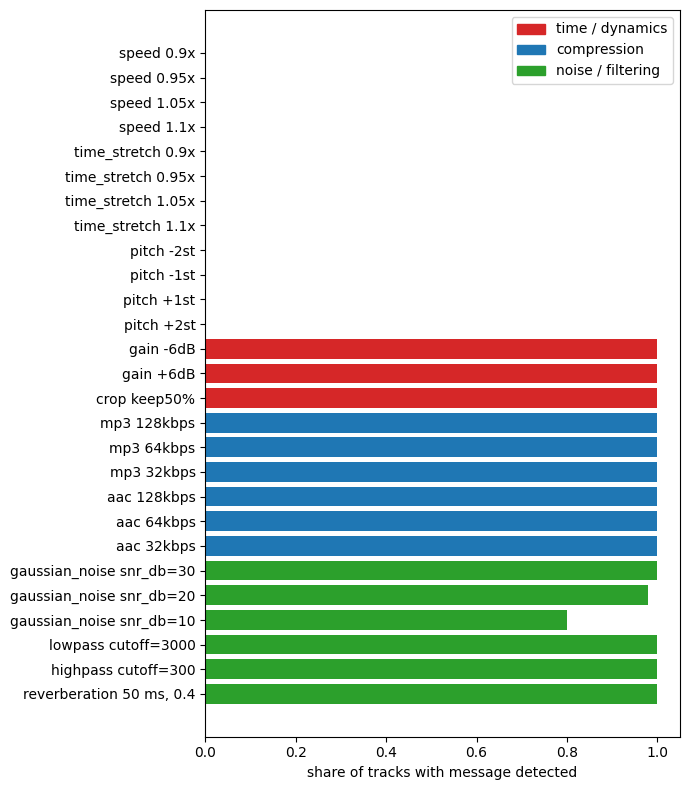

In [11]:
groups = {
    "time / dynamics": ["speed", "time_stretch", "pitch", "gain", "crop"],
    "compression": ["mp3", "aac"],
    "noise / filtering": ["gaussian_noise", "lowpass", "highpass", "reverberation"],
}
colors = {"time / dynamics": "tab:red", "compression": "tab:blue", "noise / filtering": "tab:green"}

r = rate.reset_index()
r = r[~r.attack.isin(["none", "unwatermarked"])]
r["group"] = r.attack.map({a: g for g, att in groups.items() for a in att})
r["label"] = r.attack + " " + r.params.str.replace("decay=0.4,delay_ms=50,repeats=5", "50 ms, 0.4")

fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(r.label[::-1], r.detected[::-1], color=r.group.map(colors)[::-1])
ax.set_xlim(0, 1.05)
ax.set_xlabel("share of tracks with message detected")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], labels=list(colors), loc="upper right")
plt.tight_layout()
plt.show()

- Detected in all 80 tracks: no attack, gain ±6 dB, crop to 50%, mp3 and aac (128, 64, 32 kbps), low-pass 3 kHz, high-pass 300 Hz, reverb.
- Noise: 1.00 at 30 dB, 0.98 at 20 dB, 0.80 at 10 dB.
- Not detected in any track: speed, time stretch and pitch shift, even for 5% and 1 semitone.
- False positives: none (`unwatermarked` = 0.00).

### SNR after embedding

In [12]:
s = d[d.attack == "none"]
print("all:", round(s.snr.mean(), 1), "dB mean,", round(s.snr.min(), 1), "to", round(s.snr.max(), 1))
s.groupby("genre").snr.agg(["mean", "median", "min", "max"]).round(1)

all: 31.0 dB mean, 25.5 to 51.0


,mean,median,min,max
genre,,,,
Electronic,33.8,34.3,26.6,46.9
Experimental,30.4,27.6,26.2,51.0
Folk,30.7,30.0,29.0,34.8
Hip-Hop,29.9,29.9,25.5,34.6
Instrumental,31.2,31.3,26.5,35.5
International,30.9,31.0,28.0,33.8
Pop,30.2,29.2,26.8,37.0
Rock,30.7,30.0,26.8,36.2


Mean SNR is 31 dB. Genre means are close (29.9 to 33.8 dB) and the spread inside a genre is larger than the difference between genres. SNR only measures how much the signal changed, not how it sounds. No listening test was done.

### Genres under noise

Noise is the only attack where detection is not 0 or 1.

In [13]:
n = d[d.attack == "gaussian_noise"].pivot_table(index="genre", columns="params", values="detected", aggfunc="sum")
n[["snr_db=30", "snr_db=20", "snr_db=10"]]

params,snr_db=30,snr_db=20,snr_db=10
genre,,,
Electronic,10,9,6
Experimental,10,9,9
Folk,10,10,6
Hip-Hop,10,10,9
Instrumental,10,10,8
International,10,10,9
Pop,10,10,8
Rock,10,10,9


Out of 10 tracks per genre. At 10 dB Electronic and Folk are lowest (6 of 10), the others have 8 or 9. With 10 tracks per genre this is not enough to say the genre matters. At 10 dB all 16 misses had no message found at all.

## 8. Speed with `--detect-speed`

In [14]:
a = d[(d.attack == "speed") & d.params.isin(["0.9x", "1.1x"])]
b = pd.read_csv("results/results_audiowmark_detect_speed.csv", keep_default_na=False)

print(len(b), "rows,", b.track_id.nunique(), "tracks")
pd.concat([a, b]).groupby(["method", "params"]).detected.mean().round(2)

240 rows, 80 tracks


method                   params
audiowmark               0.9x      0.0
                         1.1x      0.0
audiowmark+detect-speed  -         0.0
                         0.9x      1.0
                         1.1x      1.0
Name: detected, dtype: float64

Without the option the message is lost at 0.9x and 1.1x. With it, it is read in all 80 tracks with no bit errors. This was tested only for speed, not for time stretch or pitch shift.

The `-` row is detection on the original tracks with the option switched on (false positives): 0.00.

In [15]:
!cp /content/music-watermark-benchmark/results/results_audiowmark_detect_speed.csv /content/drive/MyDrive/wm/results_audiowmark_detect_speed_240.csv

## 9. EnCodec на audiowmark

In [16]:
from google.colab import drive
drive.mount("/content/drive")
WAV_DIR = "/content/drive/MyDrive/wm/wav"
%cd /content/music-watermark-benchmark
!pip install -q encodec==0.1.1
!ls {WAV_DIR} | wc -l
!which audiowmark
!wc -l results/results_audiowmark.csv
import torch; print("cuda:", torch.cuda.is_available())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/music-watermark-benchmark
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
80
/usr/local/bin/audiowmark
2321 results/results_audiowmark.csv
cuda: False


In [17]:
!python -m scripts.run_benchmark --method audiowmark --neural --attacks encodec --wav-dir {WAV_DIR} --limit 2

method=audiowmark  device=-  tracks=2  attacks=5  out=results/results_audiowmark.csv
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Downloading: "https://dl.fbaipublicfiles.com/encodec/v0/encodec_24khz-d7cc33bc.th" to /root/.cache/torch/hub/checkpoints/encodec_24khz-d7cc33bc.th
100% 88.9M/88.9M [00:02<00:00, 35.6MB/s]
[1/2] 2 Hip-Hop snr=30.3dB 90.4s  encodec/24kbps=0 encodec/12kbps=0 encodec/6kbps=0 encodec/3kbps=0 encodec/1.5kbps=0
[2/2] 5 Hip-Hop snr=33.7dB 81.7s  encodec/24kbps=0 encodec/12kbps=0 encodec/6kbps=0 encodec/3kbps=0 encodec/1.5kbps=0
done -> results/results_audiowmark.csv


In [18]:
!python -m scripts.run_benchmark --method audiowmark --neural --attacks encodec --wav-dir {WAV_DIR} --limit 40
!cp results/results_audiowmark.csv /content/drive/MyDrive/wm/results_audiowmark_encodec_part.csv
!python -m scripts.run_benchmark --method audiowmark --neural --attacks encodec --wav-dir {WAV_DIR}
!cp results/results_audiowmark.csv /content/drive/MyDrive/wm/results_audiowmark_encodec.csv

method=audiowmark  device=-  tracks=40  attacks=5  out=results/results_audiowmark.csv
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
[3/40] 10 Pop snr=26.8dB 95.5s  encodec/24kbps=0 encodec/12kbps=0 encodec/6kbps=0 encodec/3kbps=0 encodec/1.5kbps=0
[4/40] 140 Folk snr=34.8dB 81.7s  encodec/24kbps=0 encodec/12kbps=0 encodec/6kbps=0 encodec/3kbps=0 encodec/1.5kbps=0
[5/40] 141 Folk snr=31.8dB 80.7s  encodec/24kbps=0 encodec/12kbps=0 encodec/6kbps=0 encodec/3kbps=0 encodec/1.5kbps=0
[6/40] 148 Experimental snr=26.5dB 92.7s  encodec/24kbps=0 encodec/12kbps=0 encodec/6kbps=0 encodec/3kbps=0 encodec/1.5kbps=0
[7/40] 182 Rock snr=30.1dB 85.4s  encodec/24kbps=0 encodec/12kbps=0 encodec/6kbps=0 encodec/3kbps=0 encodec/1.5kbps=0
[8/40] 190 Folk snr=29.1dB 86.0s  encodec/24kbps=0 encodec/12kbps=0 encodec/6kbps=0 enco

## 10. Notes

- 80 tracks (10 per genre), so genre results are only a first look.
- One message and one embedding strength (default).
- The source files are already mp3, decoded to WAV.
- The speed rows in the CSV files were made with an earlier version of the speed attack (`librosa.resample`). `attacks/time_dynamics.py` now uses `resample_poly`. Not rerun.
- SNR is not perceived quality.
- EnCodec run on Colab CPU, about 80 s per track; audiowmark reads the message in 0 of 80 tracks at every bitrate